# Twenty trajectories per source

This notebook evaluates the autonomous rollout of the frozen model trained on 20 trajectories from each of the four sources. The scatter plots use the physical p-ratio measured directly at frame 499. The predefined noise-reduced mixed-T trajectory-fit metric is retained only in the final training-regime summary.


In [1]:
%matplotlib inline
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize, LogNorm
from IPython.display import display

ROOT = Path.cwd().resolve()
while not (ROOT / 'notebooks').exists():
    if ROOT.parent == ROOT:
        raise RuntimeError('Run from inside the repository.')
    ROOT = ROOT.parent
if str(ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(ROOT / 'src'))
from lss.plotting import apply_editorial_style, PAPER_COLORS, style_axes

PLOT_THEME = 'light'
apply_editorial_style(PLOT_THEME)
BASE = ROOT / 'notebooks/results/mini_temperature200_frames500'
SOURCE_LABELS = {
    'node_low': 'node optimized · low-T',
    'node_mixed': 'node optimized · mixed-T',
    'stiffness_low': 'stiffness optimized · low-T',
    'stiffness_mixed': 'stiffness optimized · mixed-T',
}
SOURCE_COLORS = {
    'node_low': PAPER_COLORS['blue'], 'node_mixed': PAPER_COLORS['sky'],
    'stiffness_low': PAPER_COLORS['red'], 'stiffness_mixed': PAPER_COLORS['orange'],
}
MODE_LABELS = {'autonomous_delta_mlp': 'autonomous rollout'}
LOW_SOURCES = ['node_low', 'stiffness_low']
MIXED_SOURCES = ['node_mixed', 'stiffness_mixed']

RUN = BASE / 'all4_twenty_each'
ONE_RUN = BASE / 'all4_one_each'
MIXED_ONLY = BASE / 'joint_mixed_only'
JOINT_LOW = BASE / 'joint_low'
EARLY_RUN = ROOT / 'notebooks/results/mini_temperature200_early_weight/joint_low_early4'
required = [RUN/'completed.json', RUN/'exposure.csv', RUN/'test/mixed_temperature_latents.csv', RUN/'test/low_temperature_latents.csv',
            ONE_RUN/'completed.json', ONE_RUN/'test/mixed_temperature_latents.csv', ONE_RUN/'test/low_temperature_latents.csv',
            MIXED_ONLY/'completed.json', MIXED_ONLY/'test/per_step.csv', MIXED_ONLY/'test/per_network.csv',
            JOINT_LOW/'test/per_network.csv', JOINT_LOW/'test/low_temperature_latents.csv',
            RUN/'test/mixed_temperature_latents_completed.json',
            RUN/'test/per_step.csv', RUN/'test/per_network.csv',
            RUN/'test/mixed_linear_fit_summary.csv',
            JOINT_LOW/'test/per_step.csv', EARLY_RUN/'completed.json',
            EARLY_RUN/'test/per_step.csv', EARLY_RUN/'test/mixed_linear_fit_summary.csv']
missing = [str(path) for path in required if not path.exists()]
if missing:
    raise FileNotFoundError('Missing frozen artifacts:\n' + '\n'.join(missing))
completed = json.loads((RUN/'completed.json').read_text())
exposure = pd.read_csv(RUN/'exposure.csv')
latents = pd.concat([pd.read_csv(RUN/'test/low_temperature_latents.csv'), pd.read_csv(RUN/'test/mixed_temperature_latents.csv')], ignore_index=True)
one_latents = pd.concat([pd.read_csv(ONE_RUN/'test/low_temperature_latents.csv'), pd.read_csv(ONE_RUN/'test/mixed_temperature_latents.csv')], ignore_index=True)
joint_low_latents = pd.read_csv(JOINT_LOW/'test/low_temperature_latents.csv')
mixed_only_step = pd.read_csv(MIXED_ONLY/'test/per_step.csv')
mixed_only_network = pd.read_csv(MIXED_ONLY/'test/per_network.csv')
joint_low_per_network = pd.read_csv(JOINT_LOW/'test/per_network.csv')
per_step = pd.read_csv(RUN/'test/per_step.csv')
per_network = pd.read_csv(RUN/'test/per_network.csv')
mixed_summary = pd.read_csv(RUN/'test/mixed_linear_fit_summary.csv')
joint_low_per_step = pd.read_csv(JOINT_LOW/'test/per_step.csv')
early_per_step = pd.read_csv(EARLY_RUN/'test/per_step.csv')
manifest = json.loads((BASE/'data_manifest.json').read_text())
temperature_rows = []
for source in MIXED_SOURCES:
    for record in manifest['datasets'][source]['records']:
        temperature_rows.append({
            'source': source,
            'trajectory_id': int(record['source_index']),
            'temperature_K': float(record['temperature_K']),
        })
temperatures = pd.DataFrame(temperature_rows)
TEMP_NORM = LogNorm(vmin=temperatures.temperature_K.min(),
                    vmax=temperatures.temperature_K.max())
TEMP_CMAP = plt.get_cmap('plasma')
assert completed['status'] == 'completed'
assert latents.groupby(['source','trajectory_id']).size().eq(500).all()
assert one_latents.groupby(['source','trajectory_id']).size().eq(500).all()
assert joint_low_latents.groupby(['source','trajectory_id']).size().eq(500).all()
print('Loaded the frozen 20-per-source model: 80 training trajectories and 320 held-out trajectories.')


Loaded the frozen 20-per-source model: 80 training trajectories and 320 held-out trajectories.


## Training data


In [2]:
table = (exposure.query("split == 'train'").groupby('source')
         .agg(trajectories=('trajectory_id','size'), frames_each=('frames','first'),
              first_md_step=('first_md_step','min'), last_md_step=('last_md_step','max')))
table.index = table.index.map(SOURCE_LABELS)
display(table)


,trajectories,frames_each,first_md_step,last_md_step
source,,,,
node optimized · low-T,20,500,0,99800
node optimized · mixed-T,20,500,0,99800
stiffness optimized · low-T,20,500,0,99800
stiffness optimized · mixed-T,20,500,0,99800


## Initial state

Colours show mixed-temperature value; positions are frozen encoder coordinates.

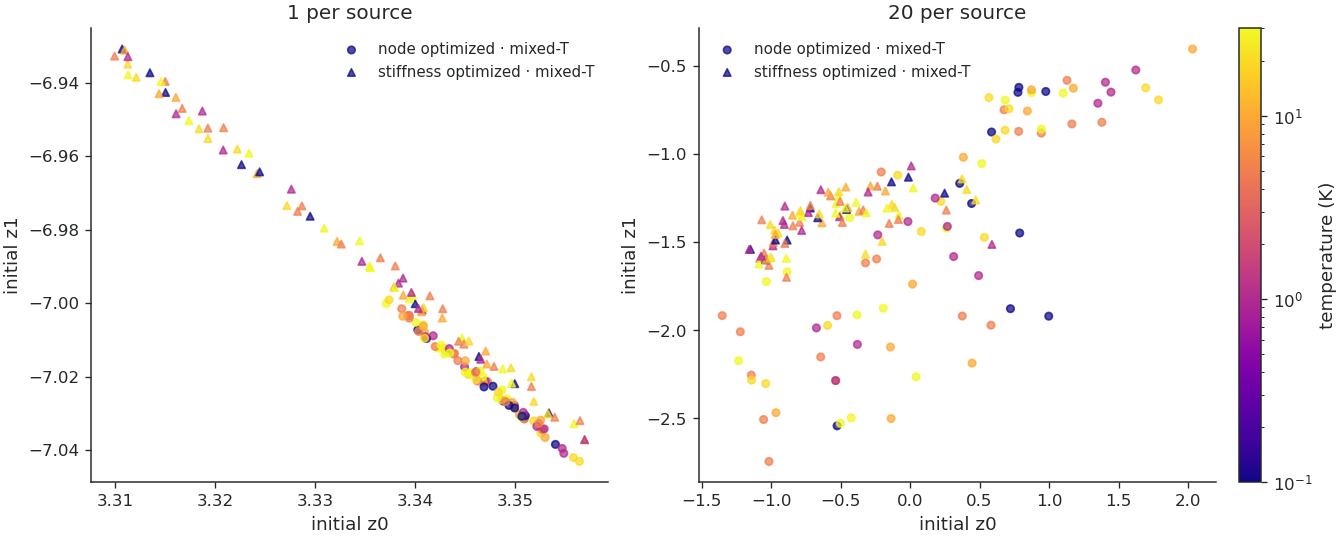

In [3]:
fig,axes=plt.subplots(1,2,figsize=(11.2,4.5),constrained_layout=True)
for ax,(name,frames) in zip(axes,[('1 per source',one_latents),('20 per source',latents)]):
    for source,marker in zip(MIXED_SOURCES,['o','^']):
        g=frames.query('source==@source and frame==0').merge(temperatures,on=['source','trajectory_id'],validate='one_to_one')
        ax.scatter(g.z0,g.z1,c=g.temperature_K,cmap=TEMP_CMAP,norm=TEMP_NORM,marker=marker,s=20,alpha=.72,label=SOURCE_LABELS[source])
    ax.set_title(name); style_axes(ax,xlabel='initial z0',ylabel='initial z1',legend=True)
fig.colorbar(plt.cm.ScalarMappable(norm=TEMP_NORM,cmap=TEMP_CMAP),ax=axes,label='temperature (K)',fraction=.025,pad=.02)
plt.show()

## Latent trajectories

Raw mixed-T paths are faint; the clearer path is a centred three-frame average.

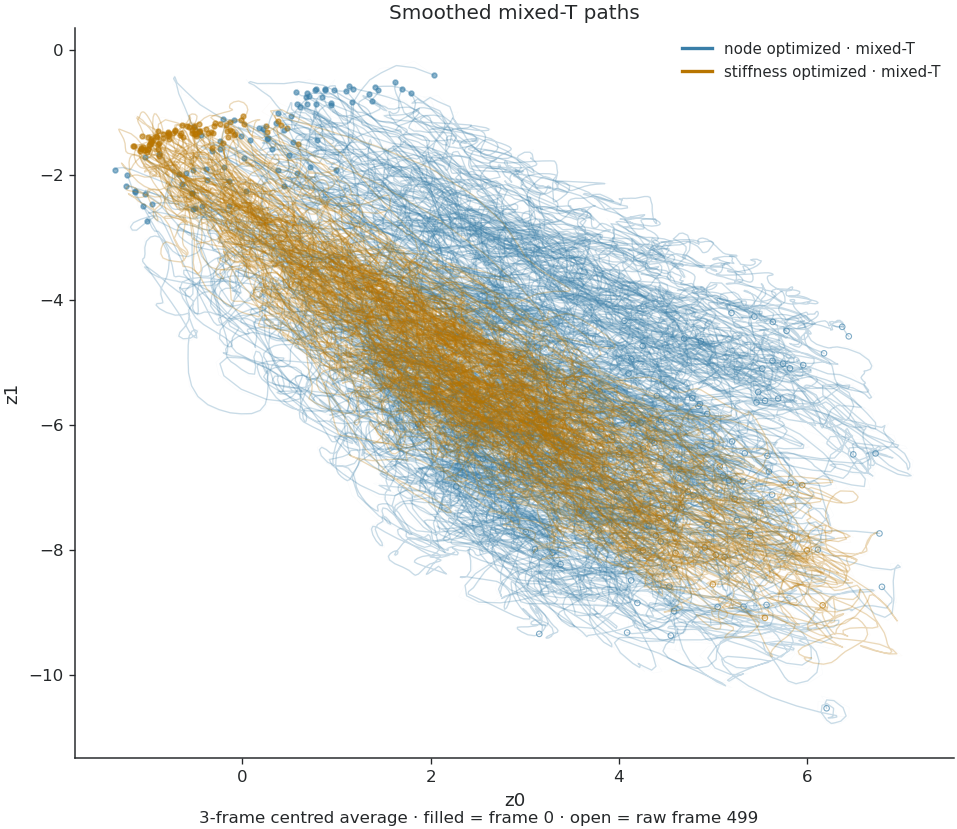

In [4]:
fig,ax=plt.subplots(figsize=(8.0,6.8),constrained_layout=True)
for source in MIXED_SOURCES:
    for _,path in latents.query('source==@source').groupby('trajectory_id'):
        path=path.sort_values('frame'); z=path[['z0','z1']].to_numpy(); smooth=z.copy(); smooth[1:-1]=(z[:-2]+z[1:-1]+z[2:])/3
        ax.plot(z[:,0],z[:,1],color=SOURCE_COLORS[source],lw=.35,alpha=.025)
        ax.plot(smooth[:,0],smooth[:,1],color=SOURCE_COLORS[source],lw=.8,alpha=.27)
        ax.scatter(z[0,0],z[0,1],s=8,color=SOURCE_COLORS[source],alpha=.55)
        ax.scatter(smooth[-1,0],smooth[-1,1],s=11,facecolors='none',edgecolors=SOURCE_COLORS[source],linewidth=.65,alpha=.65)
    ax.plot([],[],color=SOURCE_COLORS[source],lw=2,label=SOURCE_LABELS[source])
ax.set_title('Smoothed mixed-T paths'); style_axes(ax,xlabel='z0',ylabel='z1',legend=True)
fig.text(.5,-.01,'3-frame centred average · filled = frame 0 · open = raw frame 499',ha='center')
plt.show()

## Same low-T networks

The same ten held-out networks per family are shown in each frozen all-four-source encoder.

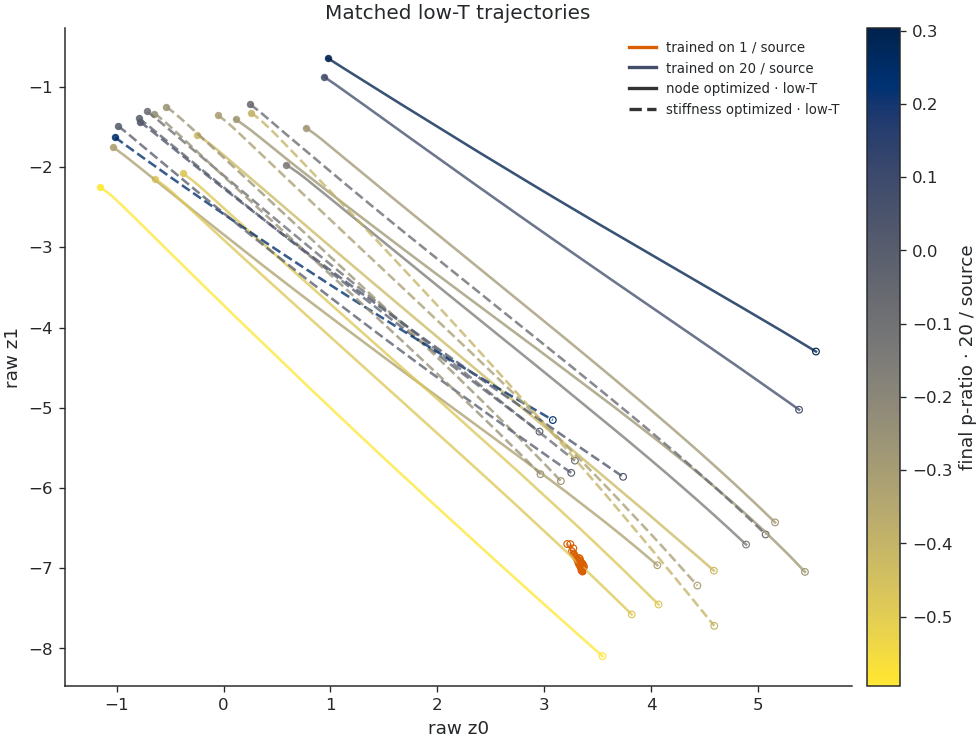

In [5]:
from matplotlib.lines import Line2D
MATCHED_IDS=np.linspace(40,119,10,dtype=int).tolist(); cmap=plt.get_cmap('cividis_r')
final=latents.query('source in @LOW_SOURCES and trajectory_id in @MATCHED_IDS and frame==499').merge(per_network.query("mode=='autonomous_delta_mlp' and frame==499")[['source','trajectory_id','true_p_ratio']],on=['source','trajectory_id'])
norm=Normalize(vmin=final.true_p_ratio.quantile(.02),vmax=final.true_p_ratio.quantile(.98))
fig,ax=plt.subplots(figsize=(8.2,6.2),constrained_layout=True)
for source,ls in zip(LOW_SOURCES,['-','--']):
    for tid in MATCHED_IDS:
        for name,frames in [('1 per source',one_latents),('20 per source',latents)]:
            path=frames.query('source==@source and trajectory_id==@tid').sort_values('frame'); z=path[['z0','z1']].to_numpy()
            colour='#d95f02' if name=='1 per source' else cmap(norm(final.query('source==@source and trajectory_id==@tid').true_p_ratio.iloc[0]))
            ax.plot(z[:,0],z[:,1],ls=ls,lw=1.2 if name=='1 per source' else 1.55,color=colour,alpha=.62 if name=='1 per source' else .78)
            ax.scatter(z[0,0],z[0,1],s=12,color=colour,alpha=.82); ax.scatter(z[-1,0],z[-1,1],s=16,facecolors='none',edgecolors=colour,linewidth=.7)
ax.set_title('Matched low-T trajectories'); style_axes(ax,xlabel='raw z0',ylabel='raw z1')
ax.legend(handles=[Line2D([0],[0],color='#d95f02',label='trained on 1 / source'),Line2D([0],[0],color=cmap(.75),label='trained on 20 / source'),Line2D([0],[0],color='#333',ls='-',label=SOURCE_LABELS['node_low']),Line2D([0],[0],color='#333',ls='--',label=SOURCE_LABELS['stiffness_low'])],fontsize=8)
fig.colorbar(plt.cm.ScalarMappable(norm=norm,cmap=cmap),ax=ax,label='final p-ratio · 20 / source',fraction=.045,pad=.02); plt.show()

## Shared response across network families

This post-hoc fit uses only the frozen low-T-joint encoder; p-ratio was not an input, loss, or selection criterion.

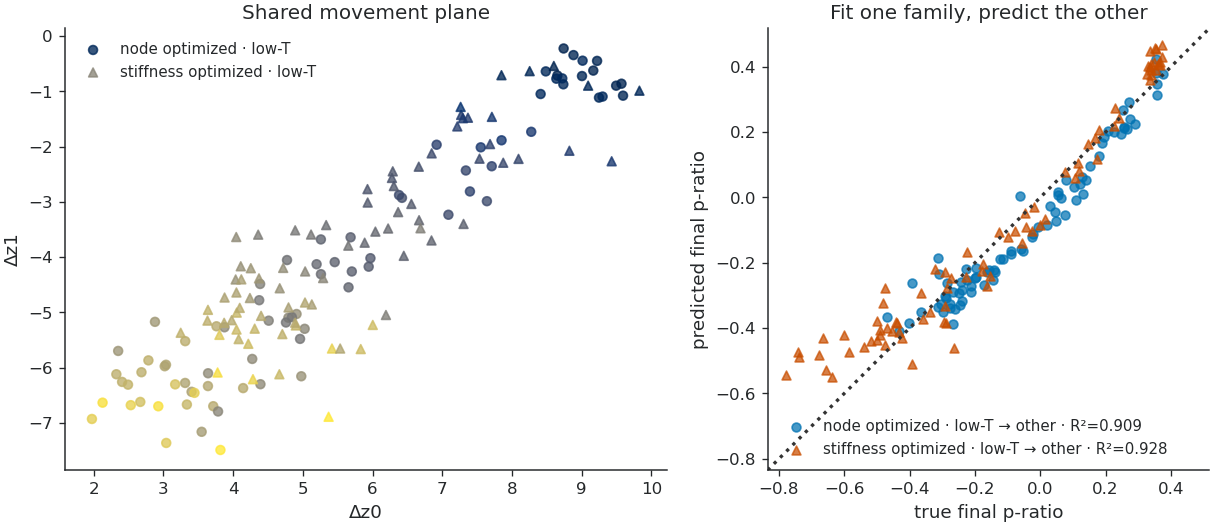

Shared fit R²: 0.946 (160/160)


In [6]:
rows=[]
for source in LOW_SOURCES:
    ini=joint_low_latents.query('source==@source and frame==0').set_index('trajectory_id')[['z0','z1']]
    end=joint_low_latents.query('source==@source and frame==499').set_index('trajectory_id')[['z0','z1']]
    response=joint_low_per_step.query("source==@source and mode=='autonomous_delta_mlp' and frame==499")
    truth=joint_low_per_network.query("source==@source and mode=='autonomous_delta_mlp' and frame==499")[['trajectory_id','true_p_ratio']].set_index('trajectory_id')
    d=(end-ini).join(truth).dropna(); d['source']=source; rows.append(d.reset_index())
shared=pd.concat(rows,ignore_index=True).rename(columns={'z0':'Δz0','z1':'Δz1','true_p_ratio':'final p-ratio'})
def fit(a,b):
    x=np.c_[np.ones(len(a)),a[['Δz0','Δz1']]]; c=np.linalg.lstsq(x,a['final p-ratio'],rcond=None)[0]; return np.c_[np.ones(len(b)),b[['Δz0','Δz1']]]@c
def r2(y,p): return 1-np.sum((y-p)**2)/np.sum((y-y.mean())**2)
fig,axes=plt.subplots(1,2,figsize=(10.8,4.4),constrained_layout=True)
for source,marker in zip(LOW_SOURCES,['o','^']):
    a=shared.query('source==@source'); axes[0].scatter(a['Δz0'],a['Δz1'],c=a['final p-ratio'],cmap='cividis_r',marker=marker,s=28,alpha=.78,label=SOURCE_LABELS[source])
    other=shared.query('source!=@source').copy(); other['predicted']=fit(a,other); score=r2(other['final p-ratio'],other.predicted)
    axes[1].scatter(other['final p-ratio'],other.predicted,marker=marker,s=28,alpha=.72,label=f'{SOURCE_LABELS[source]} → other · R²={score:.3f}')
lims=[min(axes[1].get_xlim()[0],axes[1].get_ylim()[0]),max(axes[1].get_xlim()[1],axes[1].get_ylim()[1])]; axes[1].plot(lims,lims,ls=':',color='#333')
axes[0].set_title('Shared movement plane'); style_axes(axes[0],xlabel='Δz0',ylabel='Δz1',legend=True)
axes[1].set_title('Fit one family, predict the other'); style_axes(axes[1],xlabel='true final p-ratio',ylabel='predicted final p-ratio',legend=True); axes[1].set(xlim=lims,ylim=lims,aspect='equal'); plt.show()
print('Shared fit R²:',round(r2(shared['final p-ratio'],fit(shared,shared)),3),'(160/160)')

## Early latent and physical response

Six negative-final-p-ratio networks per low-T family are shown over frames 0–20. Physical axes are normalized boundary strains, the available frozen physical response (not raw ΔL).

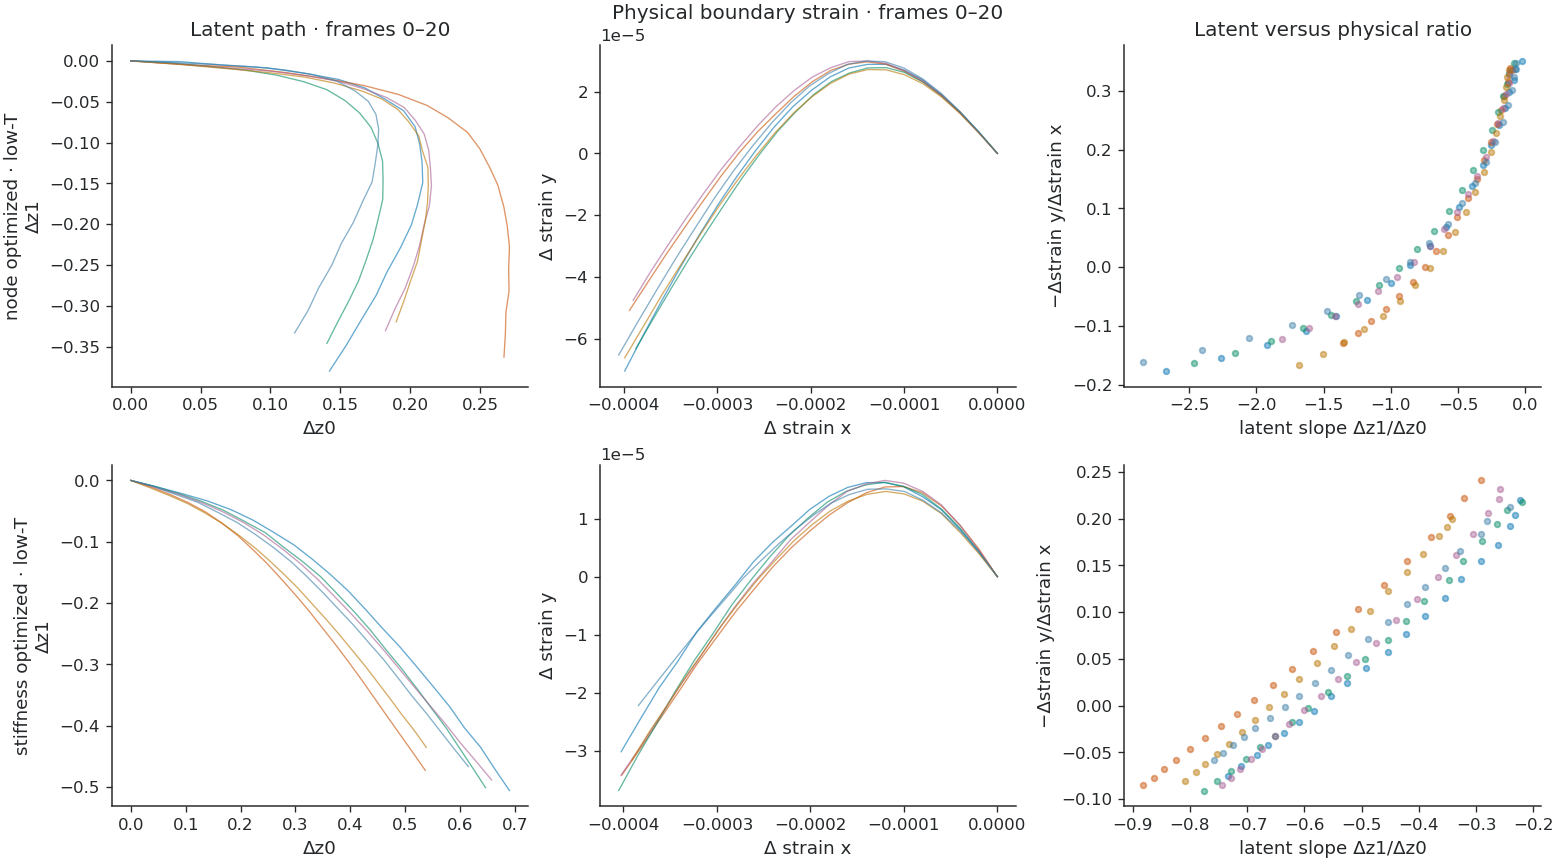

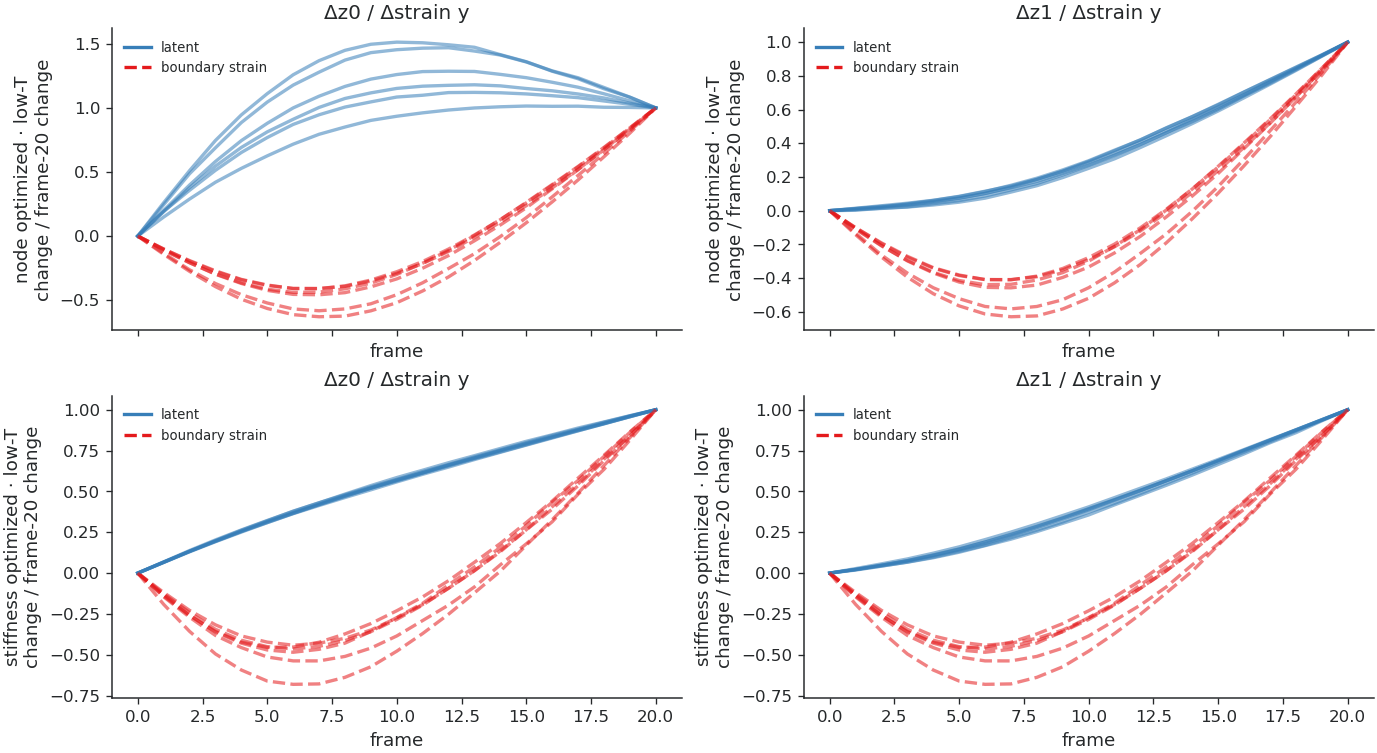

Each curve is divided by its own frame-20 change; these compare shapes, not magnitudes.


In [7]:
early_network=joint_low_per_network.query("mode=='autonomous_delta_mlp' and frame==499")
selected={s: early_network.query('source==@s and true_p_ratio<0').nsmallest(6,'true_p_ratio').trajectory_id.tolist() for s in LOW_SOURCES}
fig,axes=plt.subplots(2,3,figsize=(13,7.2),constrained_layout=True); shape=[]
for row,source in enumerate(LOW_SOURCES):
    for tid in selected[source]:
        z=joint_low_latents.query('source==@source and trajectory_id==@tid and frame<=20').sort_values('frame'); phys=joint_low_per_network.query("source==@source and trajectory_id==@tid and mode=='autonomous_delta_mlp' and frame<=20").sort_values('frame')
        dz=z[['z0','z1']].to_numpy()-z[['z0','z1']].iloc[0].to_numpy(); xy=phys[['true_boundary_strain_x','true_boundary_strain_y']].to_numpy(); xy=xy-xy[0]
        axes[row,0].plot(dz[:,0],dz[:,1],lw=.8,alpha=.6); axes[row,1].plot(xy[:,0],xy[:,1],lw=.8,alpha=.6)
        good=np.abs(dz[:,0])>1e-12; axes[row,2].scatter(dz[good,1]/dz[good,0],-xy[good,1]/xy[good,0],s=12,alpha=.45)
        shape.append((source,tid,dz,xy))
    axes[row,0].set(ylabel=SOURCE_LABELS[source]+'\nΔz1',xlabel='Δz0'); axes[row,1].set(xlabel='Δ strain x',ylabel='Δ strain y'); axes[row,2].set(xlabel='latent slope Δz1/Δz0',ylabel='−Δstrain y/Δstrain x')
axes[0,0].set_title('Latent path · frames 0–20'); axes[0,1].set_title('Physical boundary strain · frames 0–20'); axes[0,2].set_title('Latent versus physical ratio'); plt.show()
fig,axs=plt.subplots(2,2,figsize=(11.5,6.3),sharex=True,constrained_layout=True)
for row,source in enumerate(LOW_SOURCES):
    for _,_,dz,xy in [v for v in shape if v[0]==source]:
        for ax,a,b,lab in [(axs[row,0],dz[:,0],xy[:,1],'Δz0 / Δstrain y'),(axs[row,1],dz[:,1],xy[:,1],'Δz1 / Δstrain y')]:
            if abs(a[-1])>1e-12: ax.plot(np.arange(21),a/a[-1],color='#377eb8',alpha=.55)
            if abs(b[-1])>1e-12: ax.plot(np.arange(21),b/b[-1],color='#e41a1c',ls='--',alpha=.55)
            ax.set(ylabel=SOURCE_LABELS[source]+'\nchange / frame-20 change',xlabel='frame',title=lab)
for ax in axs.flat: ax.plot([],[],color='#377eb8',label='latent'); ax.plot([],[],color='#e41a1c',ls='--',label='boundary strain'); ax.legend(fontsize=8)
plt.show(); print('Each curve is divided by its own frame-20 change; these compare shapes, not magnitudes.')

## Latent dimensionality

Effective dimension and normalized path length are response-free geometry diagnostics.

,training,source,effective dimension,mean normalized trajectory arc
0,1 per source,node optimized · mixed-T,1.002,381.297
1,1 per source,stiffness optimized · mixed-T,1.001,250.825
2,20 per source,node optimized · mixed-T,1.191,63.301
3,20 per source,stiffness optimized · mixed-T,1.120,37.822


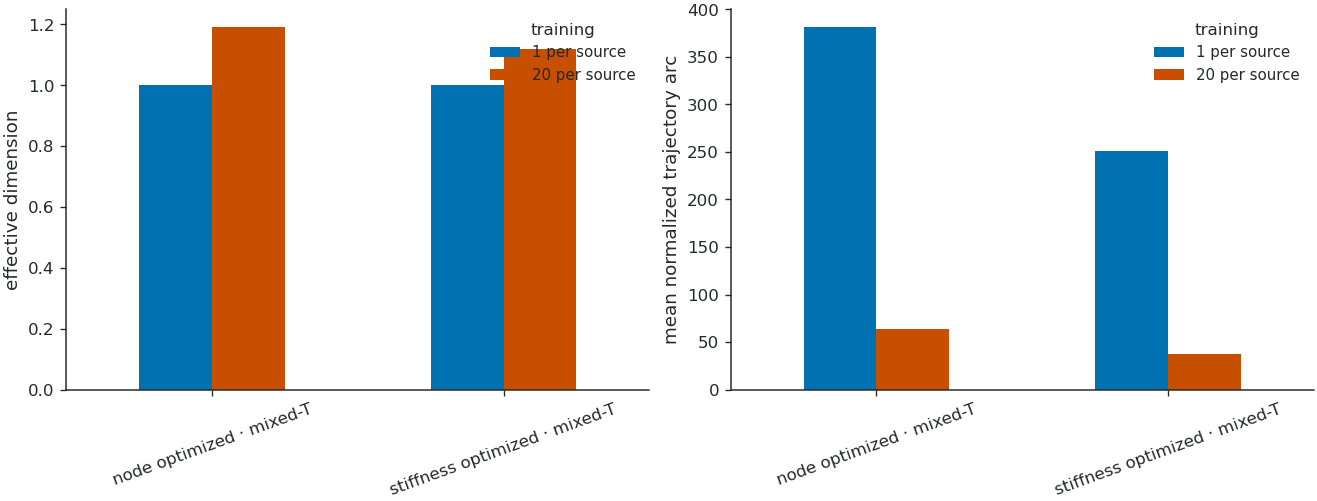

In [8]:
out=[]
for name,frames in [('1 per source',one_latents),('20 per source',latents)]:
    initial=frames.query('frame==0'); scale=np.sqrt(np.trace(np.cov(initial[['z0','z1']].to_numpy().T)))
    for source in MIXED_SOURCES:
        g=initial.query('source==@source')[['z0','z1']].to_numpy(); eig=np.linalg.eigvalsh(np.cov(g.T)).clip(min=0); effective=eig.sum()**2/(eig@eig)
        arcs=[np.linalg.norm(np.diff(x[['z0','z1']].to_numpy()/scale,axis=0),axis=1).sum() for _,x in frames.query('source==@source').groupby('trajectory_id')]
        out.append({'training':name,'source':SOURCE_LABELS[source],'effective dimension':effective,'mean normalized trajectory arc':np.mean(arcs)})
richness=pd.DataFrame(out); display(richness.round(3))
fig,axes=plt.subplots(1,2,figsize=(11,4.2),constrained_layout=True)
for ax,metric in zip(axes,['effective dimension','mean normalized trajectory arc']):
    richness.pivot(index='source',columns='training',values=metric).plot.bar(ax=ax); style_axes(ax,xlabel='',ylabel=metric); ax.tick_params(axis='x',rotation=20)
plt.show()

## Rollout

The matched-horizon curve and final scatter use the frozen all-four-source 20-trajectory model; MD step is frame × 200.

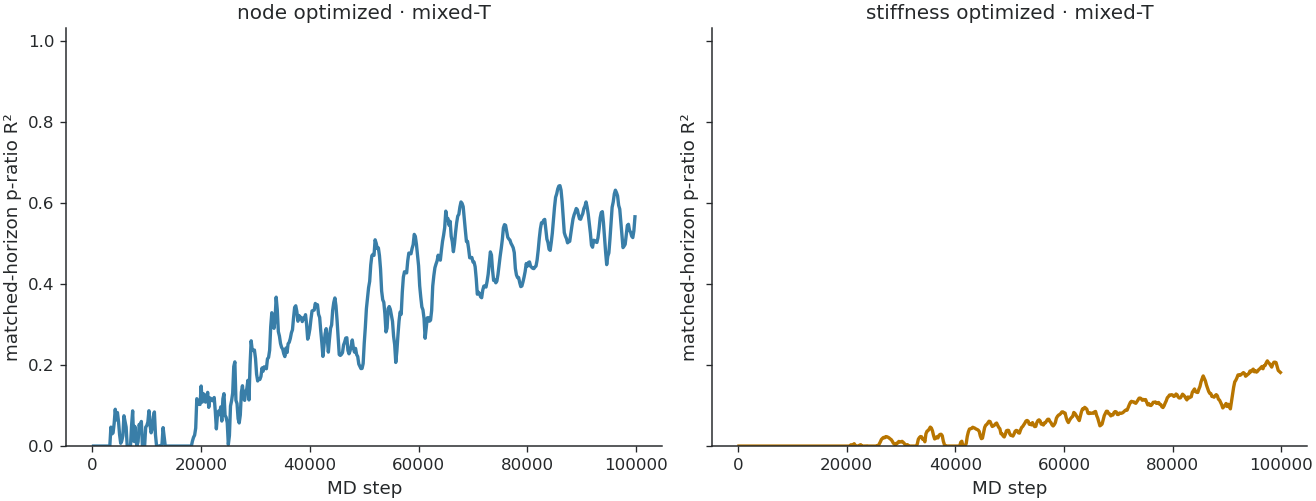

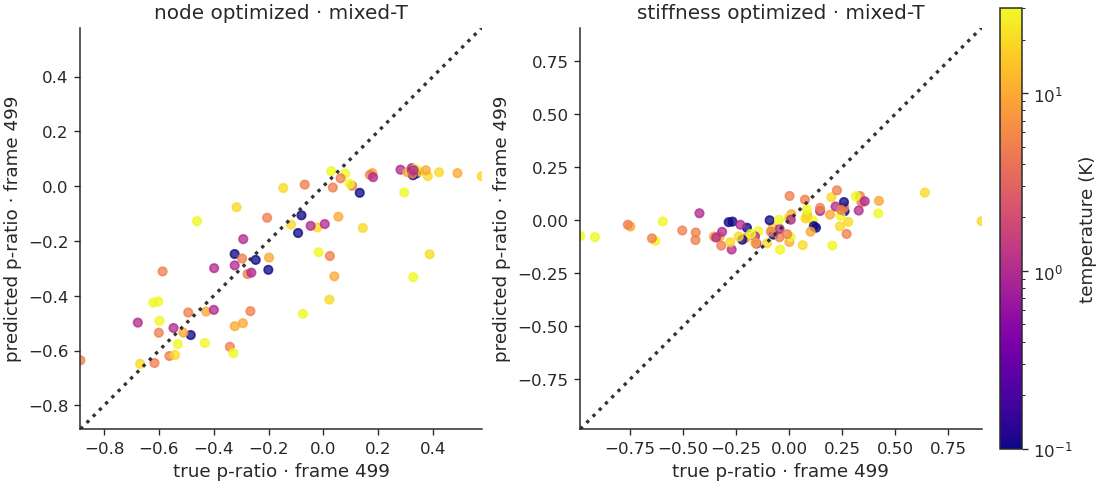

In [9]:
fig,axes=plt.subplots(1,2,figsize=(11,4.2),sharey=True,constrained_layout=True); final_rows=[]
for ax,source in zip(axes,MIXED_SOURCES):
    v=per_step.query("source==@source and mode=='autonomous_delta_mlp' and frame>0").sort_values('frame'); ax.plot(v.frame*200,v.p_ratio_r2.clip(lower=0),lw=2,color=SOURCE_COLORS[source]); ax.set_title(SOURCE_LABELS[source]); style_axes(ax,xlabel='MD step',ylabel='matched-horizon p-ratio R²'); ax.set_ylim(0,1.03)
plt.show()
fig,axes=plt.subplots(1,2,figsize=(9.2,4.2),constrained_layout=True)
for ax,source in zip(axes,MIXED_SOURCES):
    q=per_network.query("source==@source and mode=='autonomous_delta_mlp' and frame==499").merge(temperatures,on=['source','trajectory_id']); lo=min(q.true_p_ratio.min(),q.pred_p_ratio.min()); hi=max(q.true_p_ratio.max(),q.pred_p_ratio.max()); ax.scatter(q.true_p_ratio,q.pred_p_ratio,c=q.temperature_K,cmap=TEMP_CMAP,norm=TEMP_NORM,s=26,alpha=.76); ax.plot([lo,hi],[lo,hi],ls=':',color='#333'); ax.set_title(SOURCE_LABELS[source]); style_axes(ax,xlabel='true p-ratio · frame 499',ylabel='predicted p-ratio · frame 499'); ax.set(xlim=(lo,hi),ylim=(lo,hi),aspect='equal')
fig.colorbar(plt.cm.ScalarMappable(norm=TEMP_NORM,cmap=TEMP_CMAP),ax=axes,label='temperature (K)',fraction=.025,pad=.02); plt.show()

## Mixed-T-only rollout

The available frozen joint-mixed-only artifacts report direct physical p-ratio by frame, rather than the 1000-MD fitted-prefix metric.

node_mixed final R²= 0.088 (80/80)
stiffness_mixed final R²= 0.068 (80/80)


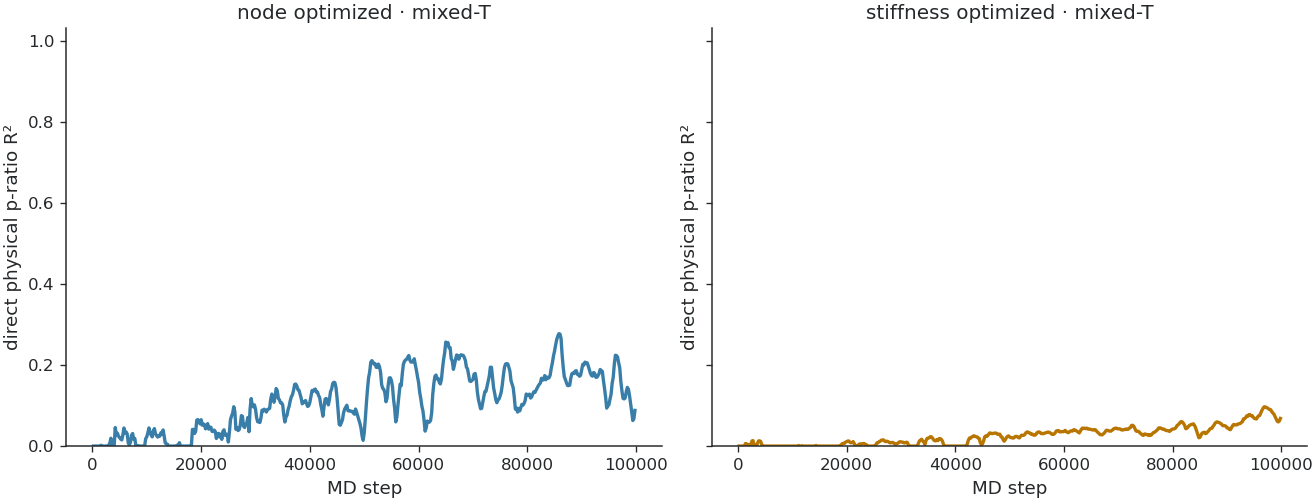

In [10]:
fig,axes=plt.subplots(1,2,figsize=(11,4.2),sharey=True,constrained_layout=True)
for ax,source in zip(axes,MIXED_SOURCES):
    curve=mixed_only_step.query("source==@source and mode=='autonomous_delta_mlp' and frame>0").sort_values('frame'); ax.plot(curve.frame*200,curve.p_ratio_r2.clip(lower=0),color=SOURCE_COLORS[source],lw=2); points=mixed_only_network.query("source==@source and mode=='autonomous_delta_mlp' and frame==499"); print(source, 'final R²=',round(curve.query('frame==499').p_ratio_r2.iloc[0],3),f"({int(curve.query('frame==499').p_ratio_valid.iloc[0])}/{int(curve.query('frame==499').p_ratio_total.iloc[0])})"); ax.set_title(SOURCE_LABELS[source]); style_axes(ax,xlabel='MD step',ylabel='direct physical p-ratio R²'); ax.set_ylim(0,1.03)
plt.show()

## Scope

This is one model seed, so there is no seed SD. Increasing from one to 20 trajectories per source also increases structural coverage. All held-out trajectories are development-test IDs 40–119 and were not used for checkpoint selection. P-ratio is evaluated only after the frozen position predictions are converted back to physical coordinates.